# Proyecto final · Análisis de los corpus y ERRANT

Corrector gramatical explicado para hispanohablantes que escriben en inglés. Este notebook sigue el pipeline de análisis:

1. **Lectura de M2** → tablas de oraciones y ediciones
2. **Metadatos por oración** → lengua materna (FCE) y nivel CEFR (W&I) desde los JSON
3. **Pares** original → corregida, validados con ERRANT
4. **Análisis**: (a) descriptivo, (b) errores ERRANT, (c) casos extremos y calidad
5. **Decisiones** para el modelo
6. **Salidas**: `datos/procesados/*.parquet` (fuera de git por licencia), `figuras/`, `resultados/*.csv`

Los corpus se descargan con `make datos` (FCE v2.1 y W&I+LOCNESS v2.1 de BEA-2019). La lectura vive en `src/corpus.py`, que reutilizará el entrenamiento.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency

RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "src"))
import corpus

CRUDOS, PROC = RAIZ / "datos" / "crudos", RAIZ / "datos" / "procesados"
FIG, RES = RAIZ / "figuras", RAIZ / "resultados"
for d in (PROC, FIG, RES):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

# Paleta validada (skill dataviz): categórica en orden fijo, secuencial de un solo azul
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
COLOR_CORPUS = {"fce": AZUL, "wi": NARANJA, "locness": AQUA}
NOMBRE_CORPUS = {"fce": "FCE", "wi": "W&I", "locness": "LOCNESS"}
SECUENCIAL = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "axes.edgecolor": "#c3c2b7",
    "xtick.color": "#898781", "ytick.color": "#898781", "grid.color": "#e1e0d9",
    "axes.grid": True, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 11, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def guardar(fig, nombre):
    fig.savefig(FIG / nombre)
    plt.show()

## 1 · Lectura de M2 y 2 · metadatos por oración

`corpus.cargar` lee cada bloque `S`/`A` (anotador 0; las líneas `noop` son oraciones sin error) y liga cada oración con su texto del JSON comparando caracteres sin espacios, con la misma normalización de puntuación que `json_to_m2.py`. No se vuelve a correr ese script: los M2 oficiales se generaron con spaCy 1.9 y uno nuevo cortaría distinto las oraciones.

- **FCE**: el `id` del JSON es del **autor** (cada uno respondió dos preguntas, `q`), así que el texto es `id#q`. Trae `l1` y edad.
- **W&I**: el nivel CEFR (A, B, C) sale del archivo; no trae lengua materna, por eso la comparación con hispanohablantes es solo dentro de FCE.
- **LOCNESS** (`N.dev`): 50 textos de nativos; queda como referencia, fuera del entrenamiento.

In [2]:
oraciones, ediciones = corpus.cargar(CRUDOS)
ediciones = ediciones.merge(oraciones[["id", "corpus", "split", "nivel", "l1"]],
                            left_on="id_oracion", right_on="id").drop(columns="id")
aprendices = oraciones[oraciones.corpus != "locness"]
train = aprendices[aprendices.split == "train"]
print(f"{len(oraciones):,} oraciones · {len(ediciones):,} ediciones")
oraciones.sample(3, random_state=1)

71,928 oraciones · 123,986 ediciones


,id,corpus,split,nivel,texto,autor,l1,edad,original,corregida,n_tokens,n_ediciones
20656,20656,fce,train,NaN,TR833*0100*2000*01#1,TR833*0100*2000*01,ja,21-25,How much do I need to bring them ?,How much do I need to bring ?,9,1
25016,25016,fce,train,NaN,TR1008*0102*2000*01#2,TR1008*0102*2000*01,sv,16-20,"What allows us to reveal parts of someone others privacy , nothing .",What allows us to reveal parts of someone else 's private life ? Nothing .,13,4
62006,62006,wi,train,C,1-81960,13944,NaN,NaN,Because I want him to talk .,Because I want him to talk .,7,0


In [3]:
resumen = (oraciones.groupby(["corpus", "split"])
           .agg(textos=("texto", "nunique"), autores=("autor", "nunique"), oraciones=("id", "size"),
                tokens=("n_tokens", "sum"), ediciones=("n_ediciones", "sum"),
                pct_sin_error=("n_ediciones", lambda s: round(100 * (s == 0).mean(), 1))))
resumen.to_csv(RES / "resumen_corpus.csv")
resumen

textos  autores  oraciones  tokens  ediciones  pct_sin_error
corpus  split                                                              
fce     dev       159       80       2191   34748       3529           36.3
        test      194       97       2695   41932       4760           32.2
        train    2116     1061      28350  454736      44382           36.3
locness dev        50       50        988   23117        950           47.8
wi      dev       300      296       3396   63856       6682           31.1
        train    3000     2425      34308  628720      63683           32.8

### Las cifras de la entrega 1, contra los archivos

In [4]:
cifras = pd.DataFrame([
    ("Pares para entrenar (FCE train + W&I train)", 62_658, len(train)),
    ("Correcciones anotadas en esos pares", 108_064, int(train.n_ediciones.sum())),
    ("Textos de estudiantes", 5_769, aprendices.texto.nunique()),
    ("Textos de hispanohablantes (FCE)", 398, oraciones[oraciones.l1 == "es"].texto.nunique()),
    ("Oraciones FCE", 33_236, int((oraciones.corpus == "fce").sum())),
    ("Oraciones W&I + LOCNESS", 38_692, int(oraciones.corpus.isin(["wi", "locness"]).sum())),
    ("% oraciones sin error (train)", 34.4, round(100 * (train.n_ediciones == 0).mean(), 1)),
    ("Errores por oración (train)", 1.72, round(train.n_ediciones.mean(), 2)),
], columns=["cifra", "entrega_1", "medido"])
cifras["coincide"] = np.isclose(cifras.entrega_1, cifras.medido, rtol=0, atol=0.051)
cifras

,cifra,entrega_1,medido,coincide
0,Pares para entrenar (FCE train + W&I train),62658.00,62658.00,True
1,Correcciones anotadas en esos pares,108064.00,108065.00,False
2,Textos de estudiantes,5769.00,5769.00,True
3,Textos de hispanohablantes (FCE),398.00,398.00,True
4,Oraciones FCE,33236.00,33236.00,True
5,Oraciones W&I + LOCNESS,38692.00,38692.00,True
6,% oraciones sin error (train),34.40,34.40,True
7,Errores por oración (train),1.72,1.72,True


Todas las cifras de la entrega 1 se reproducen salvo una: las correcciones de train son **108.065**, no 108.064. La diferencia es de una edición y no cambia ninguna conclusión, pero la próxima entrega debe usar 108.065.

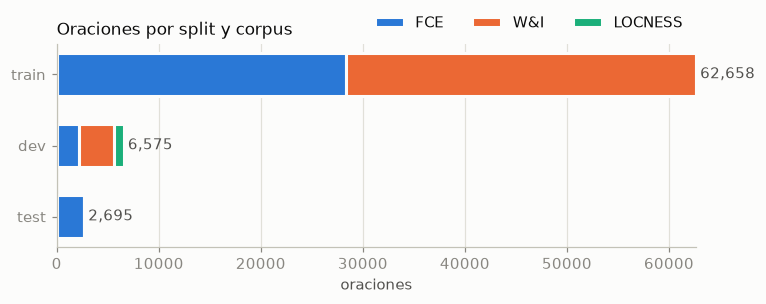

In [5]:
orden_split = ["train", "dev", "test"]
fig, ax = plt.subplots(figsize=(7.5, 2.4))
izquierda = np.zeros(len(orden_split))
for c in ["fce", "wi", "locness"]:
    n = oraciones[oraciones.corpus == c].split.value_counts().reindex(orden_split, fill_value=0).values
    ax.barh(orden_split, n, left=izquierda, color=COLOR_CORPUS[c], label=NOMBRE_CORPUS[c],
            edgecolor="#fcfcfb", linewidth=2, height=0.6)
    izquierda += n
for y, total in enumerate(izquierda):
    ax.text(total + 400, y, f"{int(total):,}", va="center", color="#52514e")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("oraciones"); ax.set_title("Oraciones por split y corpus")
ax.legend(frameon=False, ncol=3, loc="lower right", bbox_to_anchor=(1, 1))
guardar(fig, "01_oraciones_por_split.png")

## 3 · Pares original → corregida

La oración corregida se reconstruye aplicando las ediciones del anotador 0 sobre los tokens originales. Unas oraciones de hispanohablantes:

In [6]:
(oraciones.query("l1 == 'es' and n_ediciones > 0")
 .sample(6, random_state=3)[["original", "corregida", "n_ediciones"]])

,original,corregida,n_ediciones
25854,I believe I have the appropriate qualification to stay two weeks at camp California .,I believe I have the appropriate qualifications to stay two weeks at camp California .,1
13957,"First of all , in the sheet I recived , it says that DANNY BROOK was one of the actor , thing that is not true , because insted of him ,...","First of all , on the sheet I received , it says that DANNY BROOK was one of the actors . That is not true , because instead of him , th...",7
19635,"But , I heard you went on vacations to Bermuda .","But , I heard you went on vacation to Bermuda .",1
17441,But also we would like to visit The London Fashion and Leisure show that will be held at the Central kExhibition hall on Tuesday March 1...,But also we would like to visit The London Fashion and Leisure Show that will be held at the Central Exhibition Hall on Tuesday March 14...,3
28818,"Maria was nervous , but for the first time , she could talk to him as she never did before , and at the end of the day , she was the hap...","Maria was nervous , but , for the first time , she could talk to him as she never had before , and at the end of the day , she was the h...",6
14089,I would be grateful if you could send a money back because it was a horrible evening for my family and it was n't a perfect evening out .,I would be grateful if you could send me my money back because it was a horrible evening for my family and it was n't a perfect evening ...,1


### Ediciones `UNK`: errores marcados pero sin corrección

En ERRANT, `UNK` es un error que el anotador detectó pero no corrigió: la "corrección" es el mismo texto original. Una oración con `UNK` produce un par cuyo destino **conserva un error conocido**.

In [7]:
unk = ediciones[ediciones.tipo == "UNK"]
oraciones["tiene_unk"] = oraciones.id.isin(unk.id_oracion)
oraciones["sin_cambio"] = oraciones.original == oraciones.corregida
solo_unk = oraciones.tiene_unk & oraciones.sin_cambio
print(f"Ediciones UNK: {len(unk):,} ({len(unk) / len(ediciones):.1%} de todas); "
      f"correccion == original en {(unk.original == unk.correccion).mean():.1%}")
pd.DataFrame({
    "oraciones con UNK": oraciones[oraciones.tiene_unk].groupby("corpus").size(),
    "de ellas idénticas a su 'corregida'": oraciones[solo_unk].groupby("corpus").size(),
    "% de las oraciones del corpus": (100 * oraciones.groupby("corpus").tiene_unk.mean()).round(1),
}).fillna(0)

Ediciones UNK: 3,470 (2.8% de todas); correccion == original en 100.0%


,oraciones con UNK,de ellas idénticas a su 'corregida',% de las oraciones del corpus
corpus,,,
fce,1568,392,4.7
locness,18,9,1.8
wi,1648,336,4.4


In [8]:
unk.sample(6, random_state=0)[["corpus", "original", "correccion"]]

,corpus,original,correccion
105014,wi,the same harmony,the same harmony
112917,wi,flat,flat
68510,wi,and go away,and go away
69643,wi,advise you to the person starting the sport endeavor,advise you to the person starting the sport endeavor
29409,fce,patience,patience
33152,fce,received,received


**Hallazgo.** 3.470 ediciones (2,8 %) son `UNK` y en todas la corrección es idéntica al original. En train afectan a 2.779 pares (4,4 %); en 638 de ellos el `UNK` es la única edición, así que el par queda original = corregida aunque la oración tiene un error marcado. Entrenar con ellos enseña a **no corregir** errores reales, por eso se excluyen del entrenamiento (la evaluación usa los M2 oficiales sin tocarlos).

### Validación con ERRANT 3.0.2

Si los pares están bien reconstruidos, ERRANT debería recuperar las ediciones anotadas al comparar original y corregida. Sobre una muestra de 2.000 oraciones con error de train (sin `UNK`, que no cambian el texto):

- **cobertura**: ediciones anotadas que ERRANT encuentra con el mismo span y corrección;
- **precisión**: ediciones de ERRANT que estaban anotadas;
- **acuerdo de tipo**: entre las coincidentes, cuántas reciben el mismo tipo. Los M2 se clasificaron con spaCy 1.9; aquí corre spaCy 3.8, así que algo de desacuerdo es esperable.

In [9]:
import errant
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

anotador = errant.load("en")
oro = ediciones[ediciones.tipo != "UNK"].groupby("id_oracion")
muestra = train[train.id.isin(oro.groups)].sample(2000, random_state=0)
filas, cambios_tipo = [], []
for r in muestra.itertuples():
    o = anotador.parse(r.original, tokenise=False)
    c = anotador.parse(r.corregida, tokenise=False)
    auto = {(e.o_start, e.o_end, e.c_str): e.type for e in anotador.annotate(o, c)}
    gold = {(e.inicio, e.fin, e.correccion): e.tipo for e in oro.get_group(r.id).itertuples()}
    comunes = auto.keys() & gold.keys()
    cambios_tipo += [(gold[k], auto[k]) for k in comunes if gold[k] != auto[k]]
    filas.append((len(gold), len(auto), len(comunes), len(comunes) - sum(gold[k] != auto[k] for k in comunes)))
g, a, comunes, mismo = np.array(filas).sum(axis=0)
print(f"cobertura {comunes / g:.1%} · precisión {comunes / a:.1%} · acuerdo de tipo {mismo / comunes:.1%}")
pd.Series(cambios_tipo).value_counts().head(8).rename("anotado → ERRANT 3.0.2")

cobertura 86.9% · precisión 85.5% · acuerdo de tipo 94.9%


(R:OTHER, R:SPELL)       44
(R:NOUN:NUM, R:MORPH)    23
(R:OTHER, R:PRON)        22
(R:OTHER, R:VERB)        13
(R:OTHER, R:DET)         10
(R:OTHER, R:PREP)         8
(R:OTHER, R:ADV)          7
(R:ADJ:FORM, R:MORPH)     6
Name: anotado → ERRANT 3.0.2, dtype: int64

**Hallazgo.** ERRANT 3.0.2 recupera el 86,9 % de las ediciones anotadas y el 85,5 % de lo que propone estaba anotado; las diferencias son sobre todo de **cómo parte los spans** (una edición larga anotada contra dos cortas), no pares mal reconstruidos. Cuando coinciden, el tipo es el mismo en el 94,9 %. Los desacuerdos van casi siempre de `R:OTHER` (anotado) a un tipo concreto (`R:SPELL`, `R:PRON`, `R:VERB`): ERRANT 3 clasifica más fino que la versión con la que se generaron los M2.

Consecuencia para la explicación: las ediciones del modelo se tipan con ERRANT 3.0.2, así que el análisis por tipo debe leerse sabiendo que el oro tiene más `R:OTHER` del que tendría hoy.

## 4a · Descriptivo

Grupos de análisis: FCE separado por lengua materna (hispanohablantes `es` contra el resto) y W&I por nivel CEFR. La densidad de error se mide **por cada 100 tokens**, porque las oraciones largas acumulan más ediciones.

In [10]:
def grupo(df):
    return np.select(
        [df.corpus.eq("fce") & df.l1.eq("es"), df.corpus.eq("fce"), df.corpus.eq("wi"), df.corpus.eq("locness")],
        ["FCE · es", "FCE · otras L1", "W&I · " + df.nivel.fillna(""), "LOCNESS (nativos)"], "?")

ORDEN_GRUPOS = ["FCE · es", "FCE · otras L1", "W&I · A", "W&I · B", "W&I · C", "LOCNESS (nativos)"]
oraciones["grupo"] = grupo(oraciones)
ediciones["grupo"] = ediciones.id_oracion.map(oraciones.set_index("id").grupo)
por_grupo = (oraciones.groupby("grupo")
             .agg(oraciones=("id", "size"), tokens_medios=("n_tokens", "mean"),
                  pct_sin_error=("n_ediciones", lambda s: 100 * (s == 0).mean()),
                  errores_por_oracion=("n_ediciones", "mean"),
                  tokens=("n_tokens", "sum"), ediciones=("n_ediciones", "sum"))
             .reindex(ORDEN_GRUPOS))
por_grupo["errores_por_100_tokens"] = 100 * por_grupo.ediciones / por_grupo.tokens
por_grupo = por_grupo.drop(columns=["tokens", "ediciones"]).round(2)
por_grupo.to_csv(RES / "descriptivo_por_grupo.csv")
por_grupo

,oraciones,tokens_medios,pct_sin_error,errores_por_oracion,errores_por_100_tokens
grupo,,,,,
FCE · es,4617,18.04,36.11,1.85,10.26
FCE · otras L1,28619,15.66,35.99,1.54,9.85
W&I · A,11530,17.55,20.51,2.79,15.87
W&I · B,14322,18.28,28.97,1.88,10.30
W&I · C,11852,19.27,48.98,0.95,4.94
LOCNESS (nativos),988,23.40,47.77,0.96,4.11


**Hallazgo.** Los hispanohablantes de FCE no cometen muchos más errores que el resto (10,3 contra 9,9 por 100 tokens) y escriben oraciones algo más largas (18 contra 15,7 tokens). Lo que los distingue es **qué** errores cometen (sección 4b). En W&I la densidad cae con el nivel, de 15,9 en A a 4,9 en C, casi lo de los nativos de LOCNESS (4,1): el nivel CEFR captura bien la dificultad. FCE equivale a un B2 y se parece a W&I B.

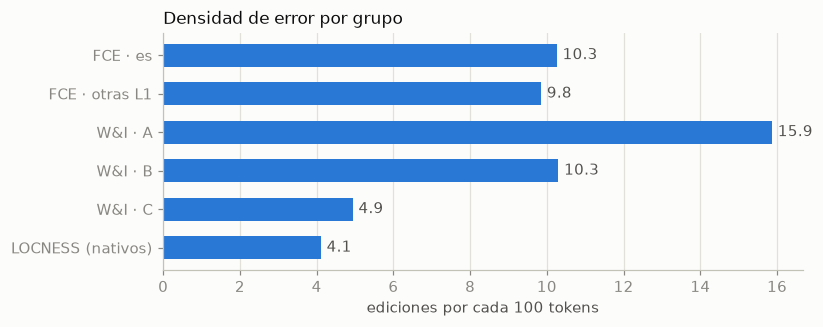

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
valores = por_grupo.errores_por_100_tokens
ax.barh(valores.index, valores.values, color=AZUL, height=0.6)
for y, v in enumerate(valores.values):
    ax.text(v + 0.15, y, f"{v:.1f}", va="center", color="#52514e")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("ediciones por cada 100 tokens")
ax.set_title("Densidad de error por grupo")
guardar(fig, "02_densidad_error.png")

### Largo de las oraciones con el tokenizador de BART

El modelo verá subpalabras BPE, no tokens de spaCy; el largo máximo se fija sobre el mayor entre original y corregida. El texto de los M2 está tokenizado con espacios (`do n't`), lo que infla un poco la cuenta frente al texto destokenizado: es una cota superior.

In [12]:
import os
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
from transformers import AutoTokenizer

tokenizador = AutoTokenizer.from_pretrained("facebook/bart-base")
largo = lambda textos: [len(ids) for ids in tokenizador(list(textos))["input_ids"]]
oraciones["bpe_original"] = largo(oraciones.original)
oraciones["bpe_corregida"] = largo(oraciones.corregida)
oraciones["bpe_max"] = oraciones[["bpe_original", "bpe_corregida"]].max(axis=1)

bpe_train = oraciones[oraciones.id.isin(train.id)].bpe_max
cortes = [32, 48, 60, 64, 96, 128]
cobertura = pd.DataFrame({"tokens BPE": cortes,
                          "% de pares de train que caben": [round(100 * (bpe_train <= L).mean(), 2) for L in cortes]})
print("percentiles 50/90/95/99/99.5:", np.percentile(bpe_train, [50, 90, 95, 99, 99.5]).round(1), "· máximo:", bpe_train.max())
cobertura

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


percentiles 50/90/95/99/99.5: [18. 35. 42. 61. 71.] · máximo: 240


,tokens BPE,% de pares de train que caben
0,32,86.74
1,48,97.11
2,60,98.96
3,64,99.24
4,96,99.86
5,128,99.95


**Hallazgo.** La mediana es de 18 tokens BPE y el 99 % de los pares mide 61 o menos: 60 cubre el 98,96 %, así que la cifra de "99 % en 60 tokens" de la entrega 1 es correcta redondeada. Con 72 tokens se cubre el 99,55 % y lo que queda fuera son oraciones de 100 a 240 tokens, casi todas de W&I: frases larguísimas encadenadas con comas que el corte de oraciones no separó.

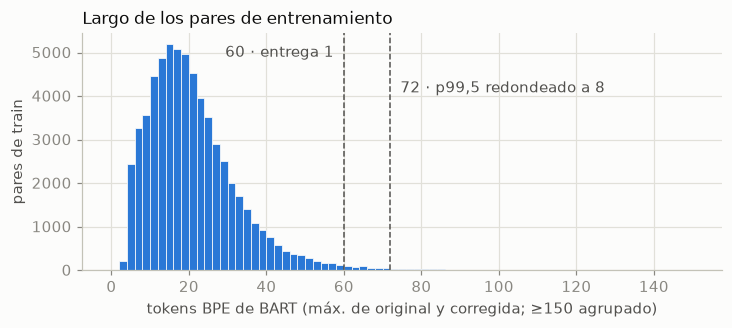

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.hist(bpe_train.clip(upper=150), bins=np.arange(0, 152, 2), color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
L = int(np.ceil(np.percentile(bpe_train, 99.5) / 8) * 8)
alto = ax.get_ylim()[1]
for x, etiqueta, y, ha in [(60, "60 · entrega 1  ", 0.9, "right"), (L, f"  {L} · p99,5 redondeado a 8", 0.75, "left")]:
    ax.axvline(x, color="#52514e", linewidth=1, linestyle="--")
    ax.text(x, alto * y, etiqueta, color="#52514e", ha=ha)
ax.set_xlabel("tokens BPE de BART (máx. de original y corregida; ≥150 agrupado)")
ax.set_ylabel("pares de train")
ax.set_title("Largo de los pares de entrenamiento")
guardar(fig, "03_largo_bpe.png")

## 4b · Errores ERRANT

Cada tipo combina una **operación** (`M` falta, `R` reemplazar, `U` sobra) con una **categoría** gramatical (25 en ERRANT). Se excluye LOCNESS, que es de nativos.

In [14]:
err = ediciones[ediciones.corpus != "locness"]
operaciones = (err.operacion.value_counts(normalize=True) * 100).round(1)
operaciones.rename({"M": "M · falta", "R": "R · reemplazar", "U": "U · sobra"}).to_frame("% de ediciones")

,% de ediciones
operacion,
R · reemplazar,62.7
M · falta,23.5
U · sobra,11.0
UNK,2.8


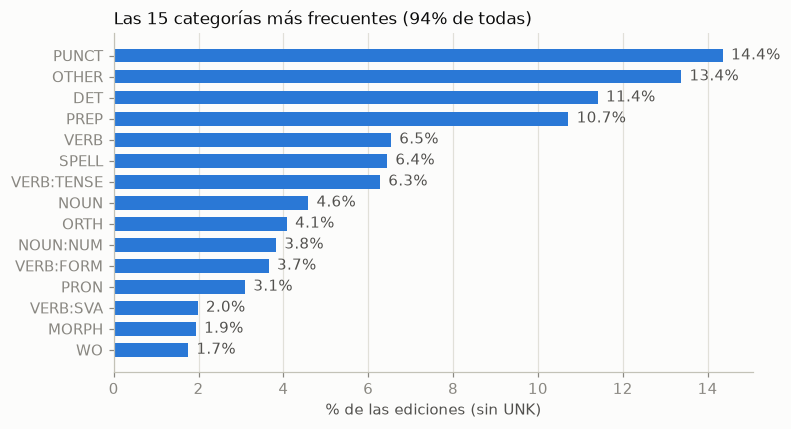

In [15]:
categorias = err[err.tipo != "UNK"].categoria.value_counts()
top = categorias.head(15)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(top.index, 100 * top.values / categorias.sum(), color=AZUL, height=0.65)
for y, v in enumerate(100 * top.values / categorias.sum()):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", color="#52514e")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de las ediciones (sin UNK)")
ax.set_title(f"Las 15 categorías más frecuentes ({top.sum() / categorias.sum():.0%} de todas)")
guardar(fig, "04_categorias.png")

### Categorías por grupo, por cada 1.000 tokens

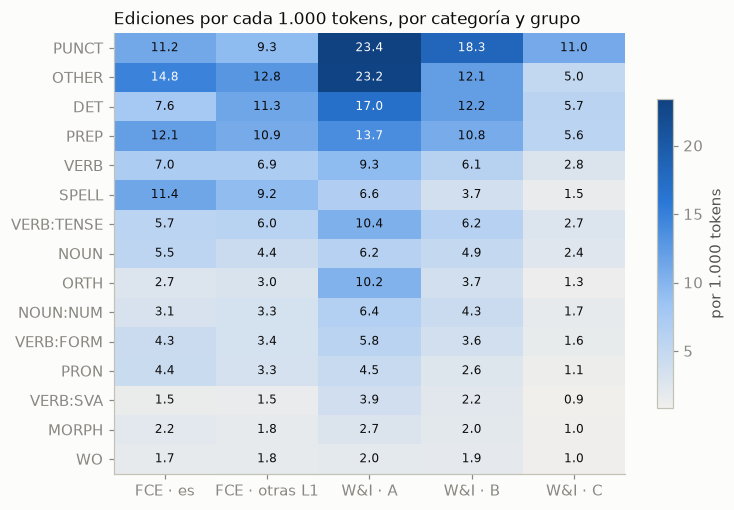

In [16]:
grupos_aprendiz = ORDEN_GRUPOS[:-1]
tokens_grupo = oraciones.groupby("grupo").n_tokens.sum()
tasa = (err[err.tipo != "UNK"].groupby(["categoria", "grupo"]).size().unstack(fill_value=0)
        .reindex(columns=grupos_aprendiz) / tokens_grupo[grupos_aprendiz] * 1000)
tasa = tasa.loc[top.index]
tasa.round(2).to_csv(RES / "categorias_por_grupo.csv")

fig, ax = plt.subplots(figsize=(7.5, 5.2))
im = ax.imshow(tasa.values, cmap=SECUENCIAL, aspect="auto")
ax.set_xticks(range(len(tasa.columns)), tasa.columns, rotation=0)
ax.set_yticks(range(len(tasa.index)), tasa.index)
ax.grid(False)
umbral = tasa.values.max() * 0.55
for i in range(tasa.shape[0]):
    for j in range(tasa.shape[1]):
        v = tasa.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="#fcfcfb" if v > umbral else "#0b0b0b")
ax.set_title("Ediciones por cada 1.000 tokens, por categoría y grupo")
fig.colorbar(im, ax=ax, shrink=0.7, label="por 1.000 tokens")
guardar(fig, "05_categorias_por_grupo.png")

### ¿Qué errores son propios de los hispanohablantes?

Dentro de FCE (mismo examen y nivel B2, así que la comparación es justa), para cada tipo con al menos 30 ediciones: tasa por 1.000 tokens en hispanohablantes contra el resto, razón entre ambas y prueba χ² de 2×2 (ediciones del tipo contra tokens) con corrección de Benjamini–Hochberg por comparar muchos tipos a la vez.

In [17]:
fce = err[(err.corpus == "fce") & (err.tipo != "UNK")]
tok_es = oraciones.query("corpus == 'fce' and l1 == 'es'").n_tokens.sum()
tok_otros = oraciones.query("corpus == 'fce' and l1 != 'es'").n_tokens.sum()
cuenta = fce.assign(es=fce.l1.eq("es")).groupby(["tipo", "es"]).size().unstack(fill_value=0)
cuenta = cuenta[cuenta.sum(axis=1) >= 30]

filas = []
for tipo, (n_otros, n_es) in cuenta.reindex(columns=[False, True], fill_value=0).iterrows():
    p = chi2_contingency([[n_es, tok_es - n_es], [n_otros, tok_otros - n_otros]])[1]
    filas.append({"tipo": tipo, "n_es": n_es, "n_otros": n_otros,
                  "tasa_es": 1000 * n_es / tok_es, "tasa_otros": 1000 * n_otros / tok_otros,
                  "razon": ((n_es + 0.5) / tok_es) / ((n_otros + 0.5) / tok_otros), "p": p})
es_vs = pd.DataFrame(filas).sort_values("p")
m = len(es_vs)
es_vs["q"] = np.minimum.accumulate((es_vs.p * m / np.arange(1, m + 1))[::-1])[::-1].clip(upper=1)
es_vs["significativo"] = es_vs.q < 0.05
es_vs = es_vs.sort_values("razon", ascending=False).round(4)
es_vs.to_csv(RES / "errores_es_vs_otros.csv", index=False)
print(f"Tasa global: {1000 * fce.l1.eq('es').sum() / tok_es:.1f} ediciones por 1.000 tokens en es "
      f"contra {1000 * fce.l1.ne('es').sum() / tok_otros:.1f} en otras L1 · {es_vs.significativo.sum()} de {m} tipos difieren")
es_vs[es_vs.significativo]

Tasa global: 100.7 ediciones por 1.000 tokens en es contra 95.1 en otras L1 · 11 de 52 tipos difieren


,tipo,n_es,n_otros,tasa_es,tasa_otros,razon,p,q,significativo
42,U:NOUN,66,200,0.7922,0.4463,1.7840,0.0001,0.0006,True
9,M:PRON,204,632,2.4487,1.4104,1.7391,0.0000,0.0000,True
29,R:PUNCT,324,1031,3.8891,2.3008,1.6921,0.0000,0.0000,True
44,U:OTHER,83,321,0.9963,0.7163,1.3970,0.0087,0.0411,True
32,R:VERB:FORM,284,1179,3.4090,2.6311,1.2974,0.0001,0.0008,True
30,R:SPELL,946,4104,11.3553,9.1585,1.2404,0.0000,0.0000,True
21,R:NOUN,339,1538,4.0692,3.4322,1.1869,0.0049,0.0254,True
27,R:PREP,584,2678,7.0100,5.9763,1.1738,0.0005,0.0032,True
26,R:OTHER,1032,4863,12.3876,10.8523,1.1419,0.0001,0.0008,True
41,U:DET,173,1205,2.0766,2.6891,0.7741,0.0016,0.0093,True


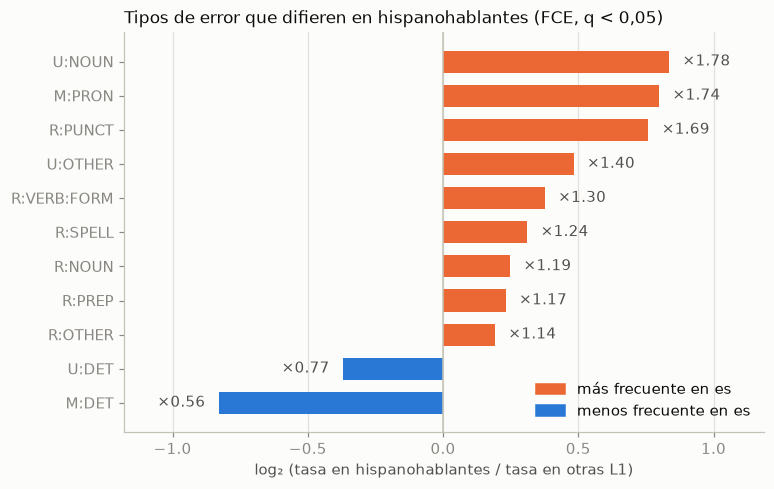

In [18]:
sig = es_vs[es_vs.significativo].sort_values("razon")
fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(sig) + 1.2))
log2 = np.log2(sig.razon)
colores = np.where(log2 > 0, NARANJA, AZUL)
ax.barh(sig.tipo, log2, color=colores, height=0.65)
for y, (v, r) in enumerate(zip(log2, sig.razon)):
    ax.text(v + (0.05 if v > 0 else -0.05), y, f"×{r:.2f}", va="center", ha="left" if v > 0 else "right", color="#52514e")
ax.axvline(0, color="#c3c2b7", linewidth=1); ax.grid(axis="y", visible=False)
ax.set_xlim(log2.min() - 0.35, log2.max() + 0.35)
ax.set_xlabel("log₂ (tasa en hispanohablantes / tasa en otras L1)")
ax.set_title("Tipos de error que difieren en hispanohablantes (FCE, q < 0,05)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=NARANJA, label="más frecuente en es"), Patch(color=AZUL, label="menos frecuente en es")],
          frameon=False, loc="lower right")
guardar(fig, "06_errores_hispanohablantes.png")

**Hallazgo.** Con el mismo examen y nivel, 11 de 52 tipos difieren de forma significativa en hispanohablantes, y el patrón coincide con la **transferencia del español**:

- **`M:PRON` ×1,74**: falta el pronombre sujeto (*"I think is very cool"* → *"I think it is very cool"*). El español omite el sujeto; es la corrección concreta más repetida después de la puntuación (`it` insertado 117 veces).
- **`R:PUNCT` ×1,69**: coma donde el inglés pide punto (oraciones unidas con coma, frecuentes en español).
- **`R:VERB:FORM` ×1,30** y **`R:PREP` ×1,17**: formas verbales (*"help to made"*) y preposiciones (*in/on/at*) calcadas.
- **`R:SPELL` ×1,24**: ortografía.
- **Menos `M:DET` (×0,56) y `U:DET` (×0,77)**: el español tiene artículos, así que se olvidan menos que en lenguas sin ellos; en "otras L1" hay muchos hablantes de coreano, ruso, japonés, polaco, turco y chino (920 de 2.071 textos).

Esto sostiene el argumento del usuario final: un corrector general trata igual estos errores, y la explicación puede priorizar los que son propios del hispanohablante.

Las correcciones concretas más repetidas en hispanohablantes, y el caso *like if* que citaba la entrega 1:

In [19]:
(fce[fce.l1 == "es"].groupby(["tipo", "original", "correccion"]).size()
 .nlargest(15).rename("veces").reset_index())

,tipo,original,correccion,veces
0,M:PUNCT,,",",379
1,U:PUNCT,",",,131
2,R:PUNCT,",",.,123
3,M:PRON,,it,117
4,M:DET,,a,113
5,U:DET,the,,109
6,M:DET,,the,97
7,M:PREP,,to,77
8,R:PREP,in,at,65
9,R:PREP,on,in,64


In [20]:
fce_or = oraciones[oraciones.corpus == "fce"]
like_if = fce_or.original.str.contains(r"\blike if\b", case=False)
pd.DataFrame({"oraciones con 'like if'": like_if.groupby(fce_or.l1.eq("es")).sum(),
              "por 1.000 oraciones": (1000 * like_if.groupby(fce_or.l1.eq("es")).mean()).round(2)}
             ).rename(index={True: "es", False: "otras L1"})

,oraciones con 'like if',por 1.000 oraciones
l1,,
otras L1,2,0.07
es,1,0.22


**Hallazgo.** *Like if* aparece solo 3 veces en todo FCE (1 de un hispanohablante): fue un buen ejemplo en la entrega 1, pero **no es un error típico en los datos**. Los ejemplos de la próxima entrega deberían salir de la tabla de arriba: pronombre sujeto omitido, coma por punto y preposiciones.

## 4c · Casos extremos y calidad

Lo que puede dañar el entrenamiento o inflar la evaluación: oraciones larguísimas, reescrituras completas, oraciones repetidas y textos del mismo autor en más de un split.

In [21]:
corto = lambda s: s if len(s) < 140 else s[:137] + "..."
oraciones.nlargest(5, "n_tokens")[["corpus", "split", "n_tokens", "bpe_max", "original"]].assign(original=lambda d: d.original.map(corto))

,corpus,split,n_tokens,bpe_max,original
37611,wi,train,220,240,"Most people say that using public transport is better than using cars , and they say that its cheaper and better for the environment , a..."
38122,wi,train,211,228,"One day I visit my friend Jimmy in New York city , he was a young man who was specialist on trains and tourism , he talked about how the..."
35193,wi,train,190,197,"But , the public transportation have a lot of future bacase a lot of reassons , first the time , if the place you want to reach finally ..."
33751,wi,train,173,205,Egypt have more historical places such as pyramids is the one of empirical in the world and more people from around the wold come to see...
35969,wi,train,168,183,"One day a man and his wife were trying to found a place shallow and without pollution for cultivate , they were poor ; they do n't have ..."


In [22]:
oraciones["densidad"] = oraciones.n_ediciones / oraciones.n_tokens.clip(lower=1)
ediciones["largo_span"] = (ediciones.fin - ediciones.inicio).clip(lower=0)
ediciones["largo_corr"] = ediciones.correccion.str.split().str.len()
reescrituras = ediciones[(ediciones.largo_span >= 5) | (ediciones.largo_corr >= 5)]
pd.Series({
    "oraciones de 1-2 tokens": int((oraciones.n_tokens <= 2).sum()),
    "oraciones con > 50% de tokens editados": int((oraciones.densidad > 0.5).sum()),
    "ediciones que reescriben ≥ 5 tokens": len(reescrituras),
    "oraciones con alguna reescritura así": reescrituras.id_oracion.nunique(),
    "máximo de ediciones en una oración": int(oraciones.n_ediciones.max()),
}).to_frame("cantidad")

,cantidad
oraciones de 1-2 tokens,2424
oraciones con > 50% de tokens editados,206
ediciones que reescriben ≥ 5 tokens,1962
oraciones con alguna reescritura así,1926
máximo de ediciones en una oración,59


In [23]:
reescrituras.sample(5, random_state=0)[["corpus", "tipo", "original", "correccion"]]

,corpus,tipo,original,correccion
888,fce,UNK,it took times to wait,it took times to wait
50678,fce,UNK,move and around the city,move and around the city
23222,fce,R:OTHER,are made - up,have their make - up put on
25767,fce,R:WO,""" Over the rainbow "" musical show","musical show "" Over the Rainbow """
61761,wi,R:OTHER,the swimming pool of my cousin,my cousin 's swimming pool


### Oraciones repetidas y fugas entre splits

In [24]:
clave = oraciones.original.str.lower()
en_train = set(clave[oraciones.split == "train"])
repetidas_train = oraciones[oraciones.split == "train"].assign(c=clave).c.value_counts()
fuga = oraciones[(oraciones.split != "train") & clave.isin(en_train)]
pares_duplicados = oraciones[oraciones.split == "train"].duplicated(["original", "corregida"]).sum()
print(f"Pares de train duplicados exactos: {pares_duplicados:,}")
print(f"Oraciones de dev/test que también están en train: {len(fuga):,} "
      f"({len(fuga) / (oraciones.split != 'train').sum():.1%}); con ≥ 6 tokens: {(fuga.n_tokens >= 6).sum()}")
repetidas_train.head(8).rename("veces en train")

Pares de train duplicados exactos: 3,636
Oraciones de dev/test que también están en train: 585 (6.3%); con ≥ 6 tokens: 122


c
yours sincerely                                               214
yours sincerely ,                                             213
yours faithfully ,                                            205
yours faithfully                                              131
dear sir ,                                                    120
dear kim ,                                                    118
unfortunately , pat was n't very good at keeping secrets .    109
i look forward to hearing from you .                          106
Name: veces en train, dtype: int64

In [25]:
autores = oraciones[oraciones.corpus != "locness"].groupby(["corpus", "autor"]).split.agg(lambda s: "+".join(sorted(set(s))))
autores.groupby("corpus").value_counts().rename("autores").to_frame()

autores
corpus split             
fce    train         1061
       test            97
       dev             80
wi     train         2325
       dev            196
       dev+train      100

**Hallazgos de calidad.**

- **Duplicados**: 3.636 pares de train son repetidos exactos, casi todos fórmulas de carta (*Yours sincerely*, *Dear Sir*) y la frase con que el examen pedía empezar la historia (*Unfortunately, Pat wasn't very good at keeping secrets*, 109 veces). Se deduplican para no sobrerrepresentarlas.
- **Fuga entre splits**: 585 oraciones de dev/test (6,3 %) también están en train, pero solo 122 tienen 6 tokens o más: son las mismas fórmulas. Impacto bajo; se reporta, no se corrige.
- **Autores**: en FCE cada autor está en un solo split. En W&I, 100 autores tienen textos en train y en dev; afecta solo a la elección de checkpoint, no al test.
- **Reescrituras**: 1.962 ediciones cambian 5 tokens o más (orden de palabras, reformulaciones). Son legítimas y se conservan; el modelo debe aprender también a reformular.

## 5 · Decisiones para el modelo

Cada hallazgo se traduce en un parámetro del entrenamiento. La tabla se calcula con los datos, así que se actualiza sola si cambian los corpus.

In [26]:
train_ids = set(train.id)
con_unk_train = oraciones.id.isin(train_ids) & oraciones.tiene_unk
dev = aprendices[aprendices.split == "dev"]
test = aprendices[aprendices.split == "test"]
decisiones = pd.DataFrame([
    ("Largo máximo (tokens BPE)", f"{L}",
     f"cubre el {100 * (bpe_train <= L).mean():.2f}% de los pares de train; 60 cubría el {100 * (bpe_train <= 60).mean():.2f}%"),
    ("Oraciones sin error", "se conservan",
     f"{100 * (train.n_ediciones == 0).mean():.1f}% de train: enseñan a no tocar lo que está bien"),
    ("Pares con UNK en train", "se excluyen del entrenamiento",
     f"{con_unk_train.sum():,} pares ({100 * con_unk_train.sum() / len(train):.1f}%) cuyo destino conserva un error marcado"),
    ("Pares duplicados exactos en train", "se deduplican", f"{pares_duplicados:,} pares"),
    ("Train", "FCE train + W&I train (A, B, C)", f"{len(train):,} pares antes de filtrar"),
    ("Dev", "FCE dev + W&I dev (A, B, C)", f"{len(dev):,} oraciones; para elegir checkpoint"),
    ("Test", "FCE test, con el subconjunto es aparte",
     f"{len(test):,} oraciones; {int((test.l1 == 'es').sum())} de hispanohablantes ({test[test.l1 == 'es'].texto.nunique()} textos)"),
    ("LOCNESS", "solo referencia", f"{(oraciones.corpus == 'locness').sum()} oraciones de nativos"),
], columns=["decisión", "valor", "por qué"])
decisiones.to_csv(RES / "decisiones.csv", index=False)
decisiones

,decisión,valor,por qué
0,Largo máximo (tokens BPE),72,cubre el 99.55% de los pares de train; 60 cubría el 98.96%
1,Oraciones sin error,se conservan,34.4% de train: enseñan a no tocar lo que está bien
2,Pares con UNK en train,se excluyen del entrenamiento,"2,779 pares (4.4%) cuyo destino conserva un error marcado"
3,Pares duplicados exactos en train,se deduplican,"3,636 pares"
4,Train,"FCE train + W&I train (A, B, C)","62,658 pares antes de filtrar"
5,Dev,"FCE dev + W&I dev (A, B, C)","5,587 oraciones; para elegir checkpoint"
6,Test,"FCE test, con el subconjunto es aparte","2,695 oraciones; 224 de hispanohablantes (20 textos)"
7,LOCNESS,solo referencia,988 oraciones de nativos


**Pendiente de decidir.** El subconjunto de hispanohablantes del test de FCE es pequeño: **20 textos, 224 oraciones**. Alcanza para ejemplos, pero un F0.5 sobre 224 oraciones tendrá un intervalo de confianza ancho. Alternativa: evaluar a los hispanohablantes en FCE dev + test (64 textos) y elegir el checkpoint solo con W&I dev y los no hispanohablantes de FCE dev.

## Resumen

| | |
|---|---|
| Datos | 62.658 pares de train, 5.587 de dev, 2.695 de test; cifras de la entrega 1 verificadas (108.065 correcciones) |
| Calidad | ERRANT 3.0.2 reproduce el 87 % de las ediciones; 4,4 % de pares con `UNK` y 3.636 duplicados se filtran |
| Largo | 72 tokens BPE cubren el 99,55 % (60 cubría el 98,96 %) |
| Usuario | Los hispanohablantes no cometen más errores, cometen otros: pronombre sujeto omitido, coma por punto, forma verbal, preposición, ortografía |

## 6 · Salidas

In [27]:
oraciones.to_parquet(PROC / "oraciones.parquet", index=False)
ediciones.to_parquet(PROC / "ediciones.parquet", index=False)
for carpeta in (PROC, RES, FIG):
    print(carpeta.relative_to(RAIZ), "→", sorted(p.name for p in carpeta.iterdir()))

datos/procesados → ['ediciones.parquet', 'oraciones.parquet']
resultados → ['categorias_por_grupo.csv', 'decisiones.csv', 'descriptivo_por_grupo.csv', 'errores_es_vs_otros.csv', 'resumen_corpus.csv']
figuras → ['01_oraciones_por_split.png', '02_densidad_error.png', '03_largo_bpe.png', '04_categorias.png', '05_categorias_por_grupo.png', '06_errores_hispanohablantes.png']
